# 01 · Unemployment and obesity in 2018

**Assignment requirement 1 · 5 points**

Compare unemployment rate (vertical axis) against obesity rate (horizontal axis), using **yellow five-point stars**. A scatter plot is appropriate because both variables are quantitative; equal-size marks avoid implying an unassigned third variable.

**Source:** `data/2018 Data.xlsx`, worksheet `2018 Data`. The workbook supplies percentage values such as 5.6, not fractions such as 0.056. All 52 jurisdictions are retained, including Washington, D.C., and Puerto Rico. The source's “Obesity Rates” field is used as supplied; its underlying definition is not provided.

Run every cell in order. The code below also appears in `scripts/01_unemployment_obesity.py`.

In [1]:
%matplotlib inline
"""Requirement 1: plot the supplied 2018 observations without changing the data."""
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MultipleLocator
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / 'data').is_dir() else Path.cwd().parent
assert (ROOT / 'data' / '2018 Data.xlsx').is_file(), 'Run from the repository or notebooks directory.'


def load_data():
    frame = pd.read_excel(ROOT / 'data' / '2018 Data.xlsx', sheet_name='2018 Data')
    columns = ['NAME', 'Unemployment Rate', 'Obesity Rates']
    frame = frame.loc[:, columns].copy()
    if frame['NAME'].isna().any() or frame['NAME'].duplicated().any():
        raise ValueError('Each observation must have a unique, nonmissing geographic name.')
    for column in columns[1:]:
        frame[column] = pd.to_numeric(frame[column], errors='raise')
        if not frame[column].between(0, 100).all():
            raise ValueError(f'{column}: missing or invalid percentage.')
    return frame


def create_figure(frame):
    with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 11,
                         'axes.spines.top': False, 'axes.spines.right': False,
                         'axes.labelcolor': '#243247', 'xtick.color': '#526174',
                         'ytick.color': '#526174', 'svg.fonttype': 'none'}):
        fig, ax = plt.subplots(figsize=(10.5, 7.2), facecolor='white')
        fig.subplots_adjust(left=.11, right=.96, top=.79, bottom=.19)
        fig.text(.11, .94, '2018  /  ECONOMY & HEALTH', fontsize=10,
                 color='#526174', weight='bold')
        fig.text(.11, .88, 'Unemployment and obesity across U.S. jurisdictions',
                 fontsize=19, weight='bold', color='#16263b')
        fig.text(.11, .835, f'{len(frame)} observations · 50 states, Washington, D.C., and Puerto Rico',
                 fontsize=11, color='#526174')
        ax.set_axisbelow(True)
        ax.grid(axis='both', color='#e7ebef', linewidth=.8)
        ax.scatter(frame['Obesity Rates'], frame['Unemployment Rate'],
                   color='yellow', marker='*', s=155, edgecolors='#665500',
                   linewidths=.8, alpha=1, zorder=3)
        ax.set(xlabel='Obesity rate (%)', ylabel='Unemployment rate (%)',
               xlim=(20, 42), ylim=(0, 17))
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
        ax.xaxis.set_major_locator(MultipleLocator(5))
        ax.yaxis.set_major_locator(MultipleLocator(2))
        ax.spines['left'].set_color('#c8d0da')
        ax.spines['bottom'].set_color('#c8d0da')
        # Label a few geographic reference points; retain every observation.
        for name, offset in [('Puerto Rico', (-12, 10)), ('Colorado', (10, -17)),
                             ('Mississippi', (-12, 10))]:
            row = frame.loc[frame['NAME'].eq(name)].iloc[0]
            ax.annotate(name, (row['Obesity Rates'], row['Unemployment Rate']),
                        xytext=offset, textcoords='offset points',
                        ha='right' if offset[0] < 0 else 'left', fontsize=9,
                        color='#36465a')
        fig.text(.11, .095, 'Each yellow star represents one jurisdiction. Rates are percentage values as supplied.',
                 fontsize=9, color='#526174')
        fig.text(.11, .065, 'Source: 2018 Data.xlsx, “2018 Data” sheet. Association does not establish causation.',
                 fontsize=9, color='#526174')
        return fig, ax


def main():
    frame = load_data()
    fig, _ = create_figure(frame)
    destination = ROOT / 'figures'
    destination.mkdir(exist_ok=True)
    for extension in ['png', 'svg', 'pdf']:
        fig.savefig(destination / f'01_unemployment_obesity.{extension}', dpi=300,
                    facecolor='white')
    print(f'Plotted all {len(frame)} observations; exported PNG, SVG, and PDF.')
    return frame, fig


## Data validation

Require unique geographic names, numeric rates, no missing values, and values between 0 and 100. Invalid input raises an error rather than silently removing observations.

In [2]:
frame = load_data()
print(f'Validated {len(frame)} observations; no missing rate values.')
frame.describe().round(2)

Validated 52 observations; no missing rate values.


,Unemployment Rate,Obesity Rates
count,52.00,52.00
mean,4.95,31.40
std,1.78,3.91
min,2.80,22.85
25%,3.88,28.55
50%,4.90,30.95
75%,5.50,34.36
max,15.10,39.70


## Required visualization

`color='yellow'` sets the required fill and `marker='*'` selects a five-point star. A dark outline keeps yellow visible against white. Selected geographic labels provide reference points without crowding all 52 marks.

Matplotlib reference: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html

Marker reference: https://matplotlib.org/stable/api/markers_api.html

Plotted all 52 observations; exported PNG, SVG, and PDF.


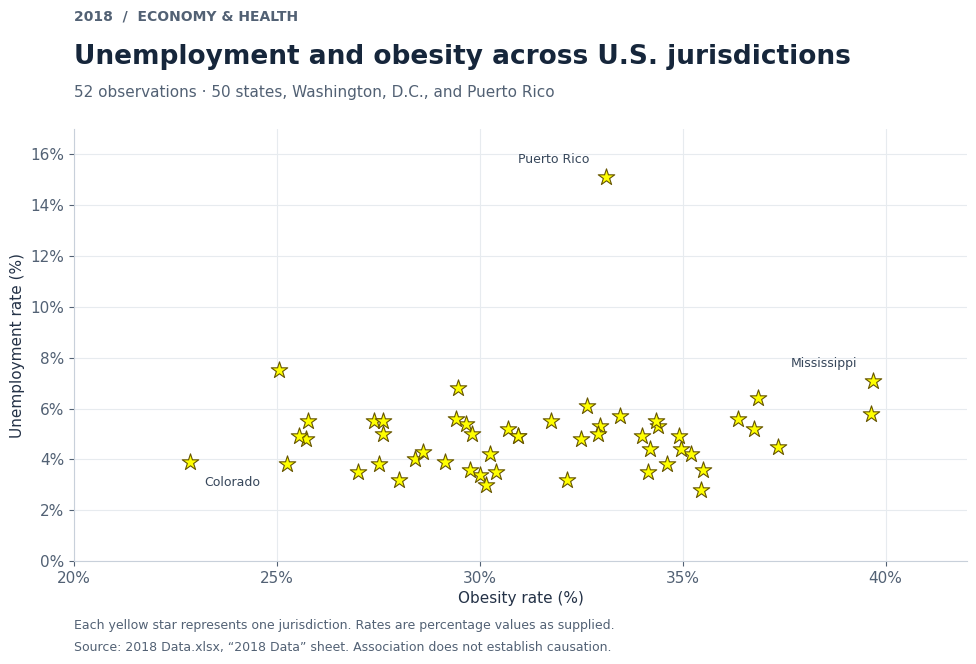

In [3]:
frame, fig = main()
assert len(fig.axes[0].collections[0].get_offsets()) == len(frame)
plt.show()

## Interpretation and limits

Most supplied unemployment rates cluster below 8%, while Puerto Rico is visibly separated at 15.1%. Obesity rates vary within that cluster, so this plot alone does not justify a strong causal claim. These are jurisdiction-level observations, not individual health or employment records. No trend line is required, and none is added.

**Exports:** `figures/01_unemployment_obesity.png` (300 dpi), `.svg`, and `.pdf`.